# Appendix figures: photo-$z$ **precision** and **bias** vs. the paper's LSST Y10 baseline

Notebooks `05b` (precision) and `05c` (bias) each re-ran an MCMC chain for the fiducial
LSST Y10 configuration ($\sigma_z/(1+z) = 0.03$, no bias) so that every curve in *those*
notebooks came from the same Monte-Carlo pairing realisation.  For the paper, however, the
baseline shown in the appendix must be the **same posterior** as the one in the main text
(Figs. 6–8, Table 3), which was produced by notebook `04a` and stored in
`../data/posteriors/forecast_w0waCDM_fixed_scatter/lsst_y10.h5`.

This notebook therefore

1. loads the `04a` LSST Y10 chain as the baseline (with the `04a` burn-in of 1000 steps, which
   reproduces the pickled samples used by `06b` bit-for-bit — checked below);
2. loads only the *degraded* chains from `05b` ($\sigma_z/(1+z) = 0.05,\,0.10$) and the *biased*
   chains from `05c` ($\Delta z_S = 0.005,\,0.01$ and $\Delta z_{D,S} = 0.01$), with their own
   burn-in of 500 steps, i.e. exactly the samples shown in `05b`/`05c`;
3. produces the two appendix corner plots (plus $w_0$–$w_a$ focus panels) and the summary
   numbers quoted in the referee response, all with the paper baseline as the reference.

The re-run fiducial chains from `05b`/`05c` are loaded too, but only as a diagnostic to show
that they are statistically indistinguishable from the paper baseline; they do not appear in
the saved figures.

No MCMC is run here — everything is read from the `.h5` backends, so the notebook runs in a
few minutes.

In [1]:
# ── Cell 1: Imports and directories ─────────────────────────────────────────
import os
import pickle
import warnings

import numpy as np
import matplotlib.pyplot as plt
import emcee

from pdspl_utils.plotting import plot_dspl_corner, plot_w0wa

warnings.filterwarnings("ignore")

%load_ext autoreload
%autoreload 2

POSTERIOR_BASELINE_DIR  = "../data/posteriors/forecast_w0waCDM_fixed_scatter"   # notebook 04a
POSTERIOR_PRECISION_DIR = "../data/posteriors/expt_photoz_precision"            # notebook 05b
POSTERIOR_BIAS_DIR      = "../data/posteriors/expt_photoz_bias"                 # notebook 05c
FIGURE_DIRECTORY        = "../figures/all_paper_figures"                        # same place as 06b/06c
os.makedirs(FIGURE_DIRECTORY, exist_ok=True)

# Burn-in used by the notebook that produced each chain.  04a discarded 1000 steps
# (that is what the paper figures/table use); 05b and 05c discarded 500.
N_BURN_BASELINE = 1000
N_BURN_EXPT     = 500

In [2]:
# ── Cell 2: Truth, labels, ranges, palette (identical to 06b) ───────────────
truth = {
    "h0": 70.0, "om": 0.3, "w0": -1.0, "wa": 0.0,
    "lambda_int":  1.0,   "lambda_sigma": 0.05,
    "gamma_pl":    2.078, "gamma_sigma":  0.16,
}
fixed_params = {"h0": 70.0}
sampled_keys = [k for k in truth if k not in fixed_params]   # column order of the .h5 chains

latex_labels = {
    "om":           r"$\Omega_{\rm m}$",
    "w0":           r"$w_0$",
    "wa":           r"$w_a$",
    "lambda_int":   r"$\overline{\lambda}_{\rm MST}$",
    "lambda_sigma": r"$\sigma({\lambda}_{\rm MST})$",
    "gamma_pl":     r"$\overline{\gamma}_{\rm pl}$",
    "gamma_sigma":  r"$\sigma({\gamma}_{\rm pl})$",
}

# Axis ranges of the main-text forecast figures (06b), so the appendix panels are
# directly comparable.  Switch to CUSTOM_RANGES_ZOOM for the tighter 05b/05c view.
custom_ranges = [
    (0, 1), (-2, 0), (-3, 3),
    (0.8, 1.2), (0.0, 3 * truth["lambda_sigma"]),
    (truth["gamma_pl"] - 0.5, truth["gamma_pl"] + 0.5),
    (0.0, 2 * truth["gamma_sigma"]),
]
CUSTOM_RANGES_ZOOM = [
    (0, 1), (-2, 0), (-3, 3),
    (truth["lambda_int"] - 0.1, truth["lambda_int"] + 0.1),
    (0.0, 0.15),
    (truth["gamma_pl"] - 0.1, truth["gamma_pl"] + 0.1),
    (0.12, 0.22),
]

# Okabe-Ito palette, same assignments as 05b / 05c
C_GREEN     = "#009E73"   # LSST Y10 baseline (as in the main text)
C_ORANGE    = "#E69F00"   # sigma_z = 0.05
C_VERMILION = "#D55E00"   # sigma_z = 0.10  /  coherent bias
C_BLUE      = "#0072B2"   # source bias 0.005
C_PURPLE    = "#CC79A7"   # source bias 0.01
C_GREY      = "#7F7F7F"   # re-run fiducial chains (diagnostic only)

In [3]:
# ── Cell 3: Helper — flat samples from an emcee .h5 backend (as in 06c) ─────
def load_h5(path, n_burn):
    if not os.path.exists(path):
        raise FileNotFoundError(path)
    reader = emcee.backends.HDFBackend(path, read_only=True)
    return reader.get_chain(discard=n_burn, thin=1, flat=True)


def scenario(name, color, h5_path, n_burn):
    samples = load_h5(h5_path, n_burn)
    print(f"  {os.path.relpath(h5_path):<70} burn-in={n_burn:<5d} -> {samples.shape}")
    return {"name": name, "color": color, "samples": samples, "backend_path": h5_path}

## Baseline: the LSST Y10 posterior from the main text (`04a`)

In [4]:
# ── Cell 4: Load the paper baseline ──────────────────────────────────────────
print("Loading the 04a baseline …")
baseline = scenario(
    r"LSST Y10 ($\sigma_z = 0.03(1+z)$, no bias) [paper baseline]",
    C_GREEN,
    f"{POSTERIOR_BASELINE_DIR}/lsst_y10.h5",
    N_BURN_BASELINE,
)

# Optional consistency check against the pickle that 06b used for the paper figures.
# The pickle is ~0.8 GB, so this is off by default; set to True to re-verify.
VERIFY_AGAINST_PKL = False
_pkl = "../data/samples/forecast_scenarios_w0waCDM_fixed_scatter.pkl"
if VERIFY_AGAINST_PKL and os.path.exists(_pkl):
    with open(_pkl, "rb") as f:
        _paper_samples = pickle.load(f)["lsst_y10"]["samples"]
    assert np.array_equal(_paper_samples, baseline["samples"]), \
        "h5 chain with burn-in 1000 does not reproduce the pickled paper samples"
    print("  ✓ baseline samples are identical to forecast_scenarios_w0waCDM_fixed_scatter.pkl['lsst_y10']")
    del _paper_samples

Loading the 04a baseline …
  ../data/posteriors/forecast_w0waCDM_fixed_scatter/lsst_y10.h5          burn-in=1000  -> (896000, 7)


In [5]:
# ── Cell 5: Summary-statistics helpers ───────────────────────────────────────
i_w0, i_wa = sampled_keys.index("w0"), sampled_keys.index("wa")


def quantiles(samples, key):
    q16, q50, q84 = np.percentile(samples[:, sampled_keys.index(key)], [16, 50, 84])
    return q50, q50 - q16, q84 - q50


def marginal_sigma(samples, key):
    # Half the 16th–84th percentile width
    q50, lo, hi = quantiles(samples, key)
    return 0.5 * (lo + hi)


def w0wa_fom(samples):
    # Dark Energy Task Force style FoM: 1 / sqrt(det Cov(w0, wa))
    cov = np.cov(samples[:, [i_w0, i_wa]], rowvar=False)
    return 1.0 / np.sqrt(np.linalg.det(cov))


def print_constraint_table(scenarios, keys):
    print(f"{'Scenario':<58} | {'Parameter':<13} | {'Median':>8} | {'-1σ':>7} | {'+1σ':>7}")
    print("-" * 105)
    for k in keys:
        for p in sampled_keys:
            q50, lo, hi = quantiles(scenarios[k]["samples"], p)
            print(f"{scenarios[k]['name']:<58} | {p:<13} | {q50:>8.3f} | {lo:>7.3f} | {hi:>7.3f}")


# Reference quantities from the paper baseline (used throughout)
ref_sigma   = {p: marginal_sigma(baseline["samples"], p) for p in sampled_keys}
ref_cov_inv = np.linalg.inv(np.cov(baseline["samples"][:, [i_w0, i_wa]], rowvar=False))
ref_fom     = w0wa_fom(baseline["samples"])
print(f"Paper baseline: sigma(w0) = {ref_sigma['w0']:.3f}, sigma(wa) = {ref_sigma['wa']:.3f}, FoM(w0,wa) = {ref_fom:.1f}")

Paper baseline: sigma(w0) = 0.443, sigma(wa) = 2.162, FoM(w0,wa) = 1.5


---
# Part 1 — Degraded photo-$z$ **precision** (chains from `05b`)

In [6]:
# ── Cell 6: Load the precision experiment ────────────────────────────────────
print("Loading 05b chains …")
# The baseline dict is shared; only the legend label is figure-specific (samples are not copied)
scenarios_precision = {
    "photoz_0.03": {**baseline, "name": r"LSST Y10 ($\sigma_z = 0.03(1+z)$)"},
    "photoz_0.05": scenario(r"LSST Y10 ($\sigma_z = 0.05(1+z)$)", C_ORANGE,
                            f"{POSTERIOR_PRECISION_DIR}/lsst_y10_photoz_0.05.h5", N_BURN_EXPT),
    "photoz_0.10": scenario(r"LSST Y10 ($\sigma_z = 0.10(1+z)$)", C_VERMILION,
                            f"{POSTERIOR_PRECISION_DIR}/lsst_y10_photoz_0.10.h5", N_BURN_EXPT),
}
# The 05b re-run of the fiducial case -- diagnostic only, not plotted in the saved figures
photoz_0p03_rerun = scenario(r"LSST Y10 ($\sigma_z = 0.03(1+z)$) [05b re-run]", C_GREY,
                             f"{POSTERIOR_PRECISION_DIR}/lsst_y10_photoz_0.03.h5", N_BURN_EXPT)

precision_keys   = list(scenarios_precision.keys())
precision_colors = {k: scenarios_precision[k]["color"] for k in precision_keys}
precision_styles = {"photoz_0.03": "-", "photoz_0.05": "--", "photoz_0.10": "-."}

Loading 05b chains …
  ../data/posteriors/expt_photoz_precision/lsst_y10_photoz_0.05.h5       burn-in=500   -> (928000, 7)
  ../data/posteriors/expt_photoz_precision/lsst_y10_photoz_0.10.h5       burn-in=500   -> (928000, 7)
  ../data/posteriors/expt_photoz_precision/lsst_y10_photoz_0.03.h5       burn-in=500   -> (928000, 7)


In [7]:
# ── Cell 7: Diagnostic — paper baseline vs. the 05b re-run of the same configuration ──
#
# The two chains differ only by the MC pairing realisation, the random 10k-system
# subsample and the sampler seed.  Their marginal constraints should agree to within
# the realisation noise, which is what justifies swapping the re-run for the paper chain.
print(f"{'Parameter':<13} | {'paper baseline':>22} | {'05b re-run':>22} | {'Δmedian / σ':>11}")
print("-" * 80)
for p in sampled_keys:
    q_a = quantiles(baseline["samples"], p)
    q_b = quantiles(photoz_0p03_rerun["samples"], p)
    print(f"{p:<13} | {q_a[0]:>7.3f} -{q_a[1]:.3f} +{q_a[2]:.3f} | "
          f"{q_b[0]:>7.3f} -{q_b[1]:.3f} +{q_b[2]:.3f} | {(q_b[0] - q_a[0]) / ref_sigma[p]:>+11.2f}")
print(f"\nFoM(w0,wa): paper baseline = {ref_fom:.1f}, 05b re-run = {w0wa_fom(photoz_0p03_rerun['samples']):.1f}")

Parameter     |         paper baseline |             05b re-run | Δmedian / σ
--------------------------------------------------------------------------------
om            |   0.399 -0.169 +0.130 |   0.408 -0.164 +0.129 |       +0.06
w0            |  -0.990 -0.437 +0.450 |  -0.976 -0.454 +0.446 |       +0.03
wa            |  -0.053 -2.673 +1.651 |  -0.220 -2.614 +1.741 |       -0.08
lambda_int    |   0.994 -0.019 +0.019 |   0.993 -0.020 +0.021 |       -0.03
lambda_sigma  |   0.045 -0.030 +0.031 |   0.048 -0.032 +0.033 |       +0.09
gamma_pl      |   2.094 -0.035 +0.035 |   2.096 -0.038 +0.037 |       +0.05
gamma_sigma   |   0.164 -0.032 +0.017 |   0.162 -0.036 +0.018 |       -0.07

FoM(w0,wa): paper baseline = 1.5, 05b re-run = 1.4


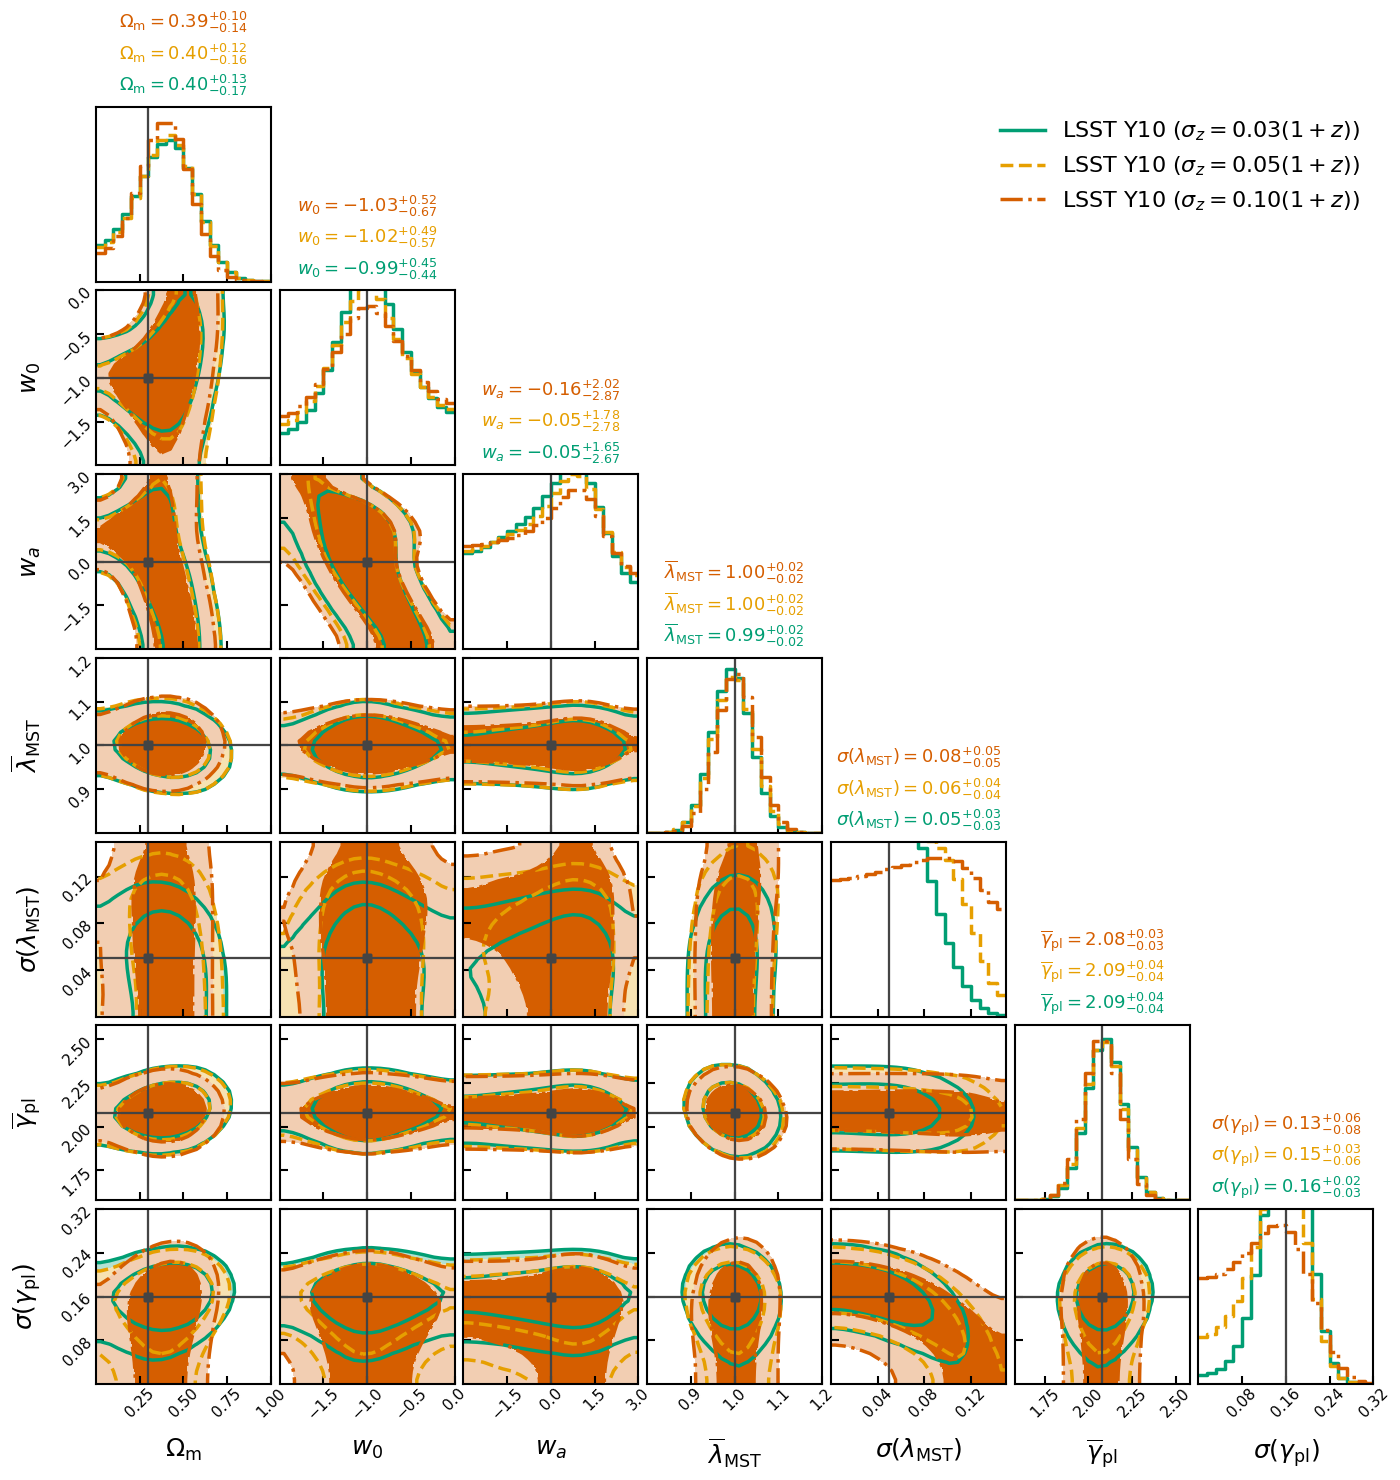

In [8]:
# ── Cell 8: Appendix figure — corner plot, degraded precision ────────────────
fig_precision = plot_dspl_corner(
    scenarios=scenarios_precision, truth=truth, fixed_params=fixed_params,
    scenarios_to_plot=precision_keys,
    custom_ranges=custom_ranges, latex_labels=latex_labels, figsize=(14, 14),
    show_multiple_titles=True,
    custom_colors_dict=precision_colors,
    custom_linestyles_dict=precision_styles,
    save_path=f"{FIGURE_DIRECTORY}/lsst_y10_photoz_precision_forecast_w0waCDM.pdf",
)
plt.show()

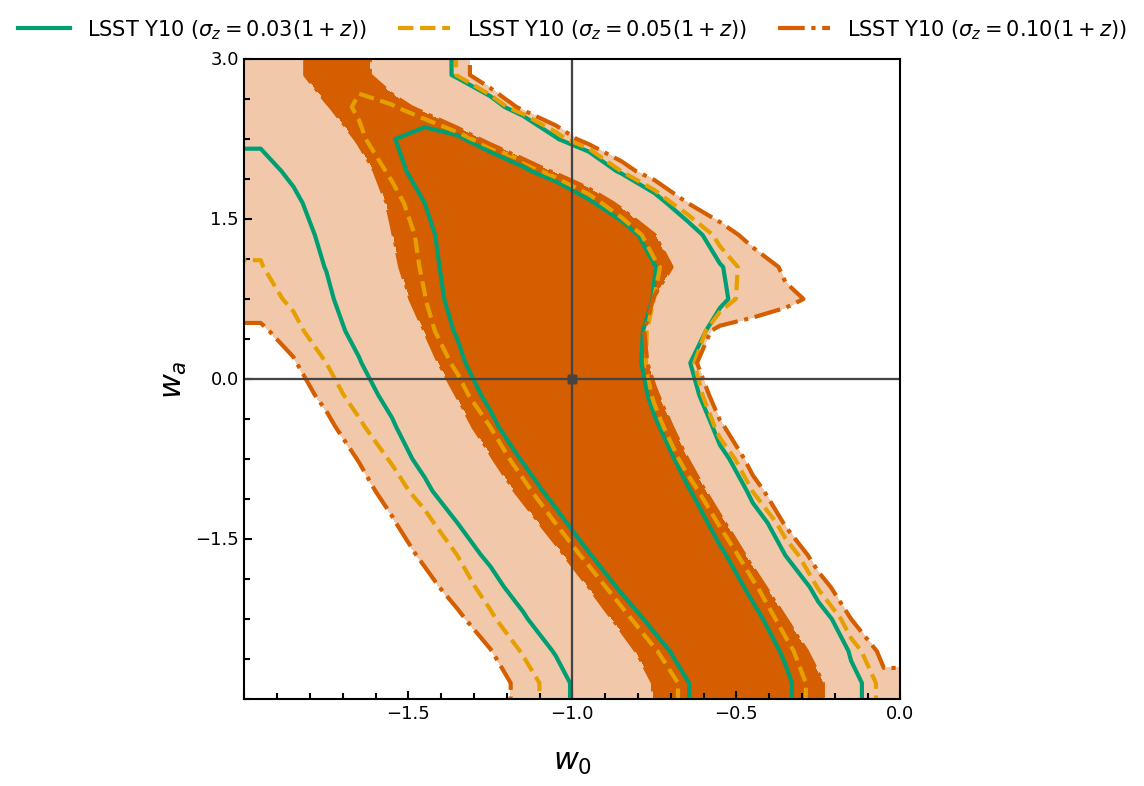

In [9]:
# ── Cell 9: w0–wa focus panel, degraded precision ────────────────────────────
fig_precision_w0wa, _ = plot_w0wa(
    scenarios_precision, truth, fixed_params,
    scenarios_to_plot=precision_keys,
    ranges=[custom_ranges[1], custom_ranges[2]],
    colors=precision_colors,
    linestyles=precision_styles,
    linewidths={k: 3.0 for k in precision_keys},
)
fig_precision_w0wa.savefig(f"{FIGURE_DIRECTORY}/lsst_y10_photoz_precision_w0wa.pdf", bbox_inches="tight")
plt.show()

In [10]:
# ── Cell 10: Precision — constraint summary and degradation factors ──────────
print_constraint_table(scenarios_precision, precision_keys)

# How much constraining power is lost, and how the degraded LSST Y10 sample compares with
# the smaller spectroscopic samples and the DSPL benchmark of the main text (all from 04a).
print("\nLoading 04a comparison chains …")
comparison = {
    "lsst_4most_spec-z":         scenario(r"PDSPL (4MOST $z^{\rm spec}$)",                    C_PURPLE, f"{POSTERIOR_BASELINE_DIR}/lsst_4most_spec-z.h5",         N_BURN_BASELINE),
    "lsst_4most_spec-z_sigma_v": scenario(r"PDSPL (4MOST $z^{\rm spec}$ + $\sigma_{v,D}$)",   C_BLUE,   f"{POSTERIOR_BASELINE_DIR}/lsst_4most_spec-z_sigma_v.h5", N_BURN_BASELINE),
    "DSPL":                      scenario("DSPL (500 lenses)",                                 C_GREY,   f"{POSTERIOR_BASELINE_DIR}/DSPL.h5",                      N_BURN_BASELINE),
}

print(f"\n{'Scenario':<58} | {'σ(w0)':>7} | {'σ(wa)':>7} | {'FoM':>7} | {'FoM/FoM_base':>12}")
print("-" * 105)
for k, sc in {**scenarios_precision, **comparison}.items():
    fom = w0wa_fom(sc["samples"])
    print(f"{sc['name']:<58} | {marginal_sigma(sc['samples'], 'w0'):>7.3f} | "
          f"{marginal_sigma(sc['samples'], 'wa'):>7.3f} | {fom:>7.1f} | {fom / ref_fom:>12.3f}")
print("\n(FoM ratio is relative to the paper's LSST Y10 baseline; values below 1 indicate lost constraining power.)")

Scenario                                                   | Parameter     |   Median |     -1σ |     +1σ
---------------------------------------------------------------------------------------------------------
LSST Y10 ($\sigma_z = 0.03(1+z)$)                          | om            |    0.399 |   0.169 |   0.130
LSST Y10 ($\sigma_z = 0.03(1+z)$)                          | w0            |   -0.990 |   0.437 |   0.450
LSST Y10 ($\sigma_z = 0.03(1+z)$)                          | wa            |   -0.053 |   2.673 |   1.651
LSST Y10 ($\sigma_z = 0.03(1+z)$)                          | lambda_int    |    0.994 |   0.019 |   0.019
LSST Y10 ($\sigma_z = 0.03(1+z)$)                          | lambda_sigma  |    0.045 |   0.030 |   0.031
LSST Y10 ($\sigma_z = 0.03(1+z)$)                          | gamma_pl      |    2.094 |   0.035 |   0.035
LSST Y10 ($\sigma_z = 0.03(1+z)$)                          | gamma_sigma   |    0.164 |   0.032 |   0.017
LSST Y10 ($\sigma_z = 0.05(1+z)$)             

---
# Part 2 — Unrecognised photo-$z$ **bias** (chains from `05c`)

In `05c` the Asimov data were generated at the true redshifts while the likelihood was given
shifted redshifts, $z_{\rm obs} = z + b\,(1+z)$, together with the fiducial
$\sigma_z/(1+z) = 0.03$ error model.  Any displacement of the posterior is a pure accuracy
effect.  The paper baseline is the natural "no bias" reference: it is the same configuration
($\sigma_z/(1+z) = 0.03$, $b = 0$) as the `05c` control chain.

In [11]:
# ── Cell 11: Load the bias experiment ────────────────────────────────────────
print("Loading 05c chains …")
scenarios_bias = {
    "unbiased":      {**baseline, "name": "No bias"},
    "source_0.005":  scenario(r"$\Delta z_S = +0.005(1+z)$",    C_BLUE,      f"{POSTERIOR_BIAS_DIR}/source_0.005.h5",  N_BURN_EXPT),
    "source_0.01":   scenario(r"$\Delta z_S = +0.01(1+z)$",     C_PURPLE,    f"{POSTERIOR_BIAS_DIR}/source_0.01.h5",   N_BURN_EXPT),
    "coherent_0.01": scenario(r"$\Delta z_{D,S} = +0.01(1+z)$", C_VERMILION, f"{POSTERIOR_BIAS_DIR}/coherent_0.01.h5", N_BURN_EXPT),
}
# The 05c unbiased control -- diagnostic only (same 10k systems as the biased chains)
unbiased_rerun = scenario("No bias [05c re-run]", C_GREY, f"{POSTERIOR_BIAS_DIR}/unbiased.h5", N_BURN_EXPT)

bias_keys   = list(scenarios_bias.keys())
bias_colors = {k: scenarios_bias[k]["color"] for k in bias_keys}
bias_styles = {"unbiased": "-", "source_0.005": "--", "source_0.01": "-.", "coherent_0.01": ":"}
bias_b      = {"unbiased": (0.0, 0.0), "source_0.005": (0.0, 0.005),
               "source_0.01": (0.0, 0.01), "coherent_0.01": (0.01, 0.01)}   # (b_D, b_S)

Loading 05c chains …
  ../data/posteriors/expt_photoz_bias/source_0.005.h5                    burn-in=500   -> (928000, 7)
  ../data/posteriors/expt_photoz_bias/source_0.01.h5                     burn-in=500   -> (928000, 7)
  ../data/posteriors/expt_photoz_bias/coherent_0.01.h5                   burn-in=500   -> (928000, 7)
  ../data/posteriors/expt_photoz_bias/unbiased.h5                        burn-in=500   -> (928000, 7)


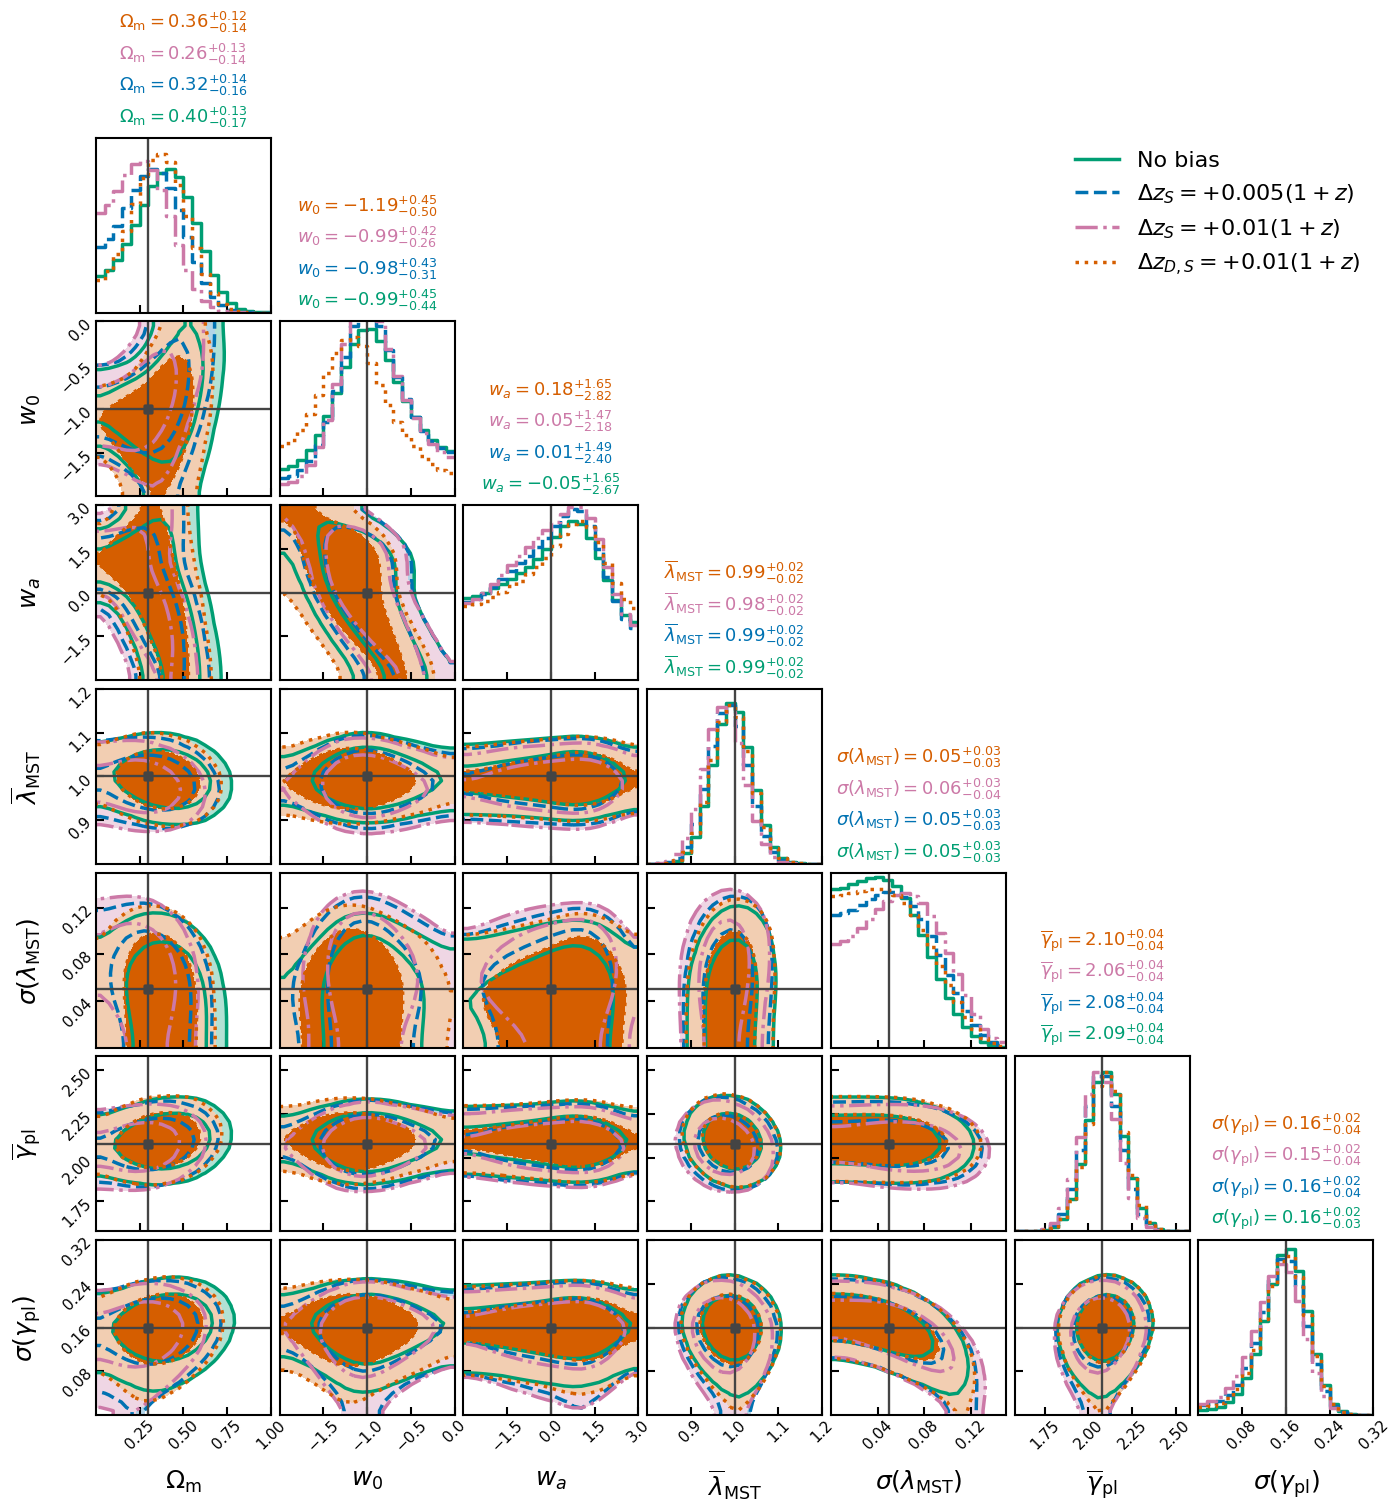

In [12]:
# ── Cell 12: Appendix figure — corner plot, photo-z bias ─────────────────────
fig_bias = plot_dspl_corner(
    scenarios=scenarios_bias, truth=truth, fixed_params=fixed_params,
    scenarios_to_plot=bias_keys,
    custom_ranges=custom_ranges, latex_labels=latex_labels, figsize=(14, 14),
    show_multiple_titles=True,
    custom_colors_dict=bias_colors,
    custom_linestyles_dict=bias_styles,
    save_path=f"{FIGURE_DIRECTORY}/lsst_y10_photoz_bias_forecast_w0waCDM.pdf",
)
plt.show()

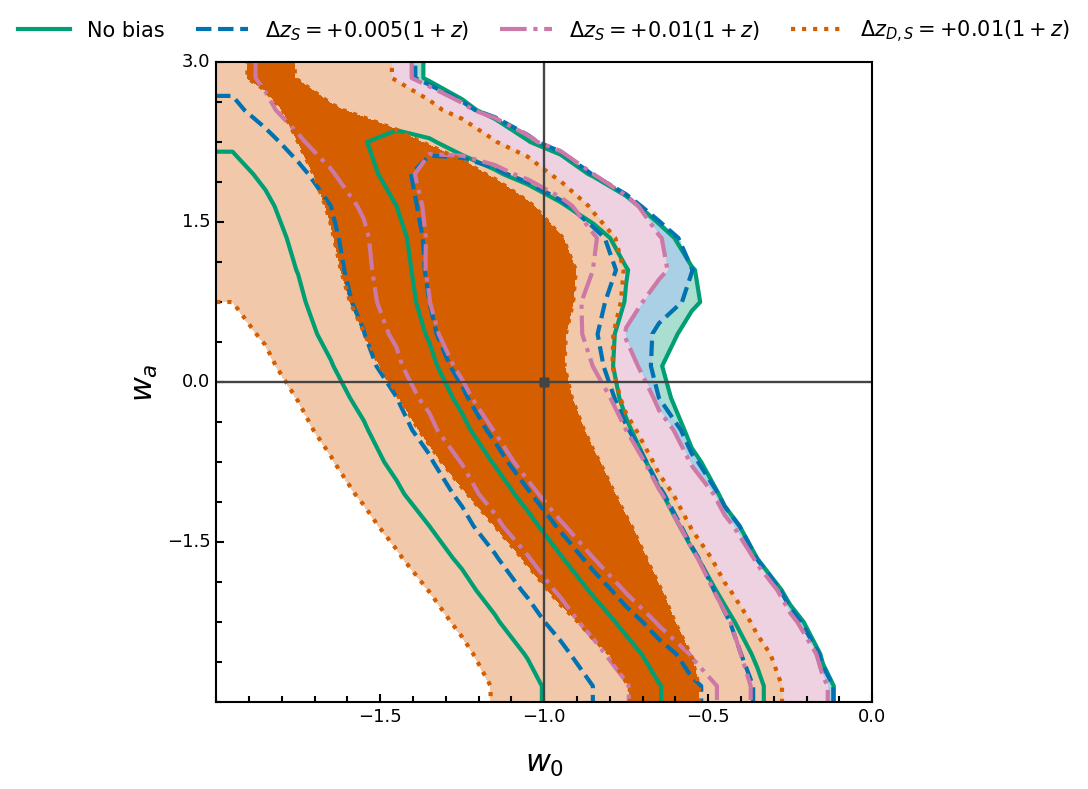

In [13]:
# ── Cell 13: w0–wa focus panel, photo-z bias ─────────────────────────────────
fig_bias_w0wa, _ = plot_w0wa(
    scenarios_bias, truth, fixed_params,
    scenarios_to_plot=bias_keys,
    ranges=[custom_ranges[1], custom_ranges[2]],
    colors=bias_colors,
    linestyles=bias_styles,
    linewidths={k: 3.0 for k in bias_keys},
)
fig_bias_w0wa.savefig(f"{FIGURE_DIRECTORY}/lsst_y10_photoz_bias_w0wa.pdf", bbox_inches="tight")
plt.show()

In [14]:
# ── Cell 14: Bias — displacement of the posterior from the truth ─────────────
#
# Shifts are quoted in units of the paper baseline's 1σ marginal error, and the (w0, wa)
# displacement uses the baseline covariance.  The 05c re-run control is listed as well:
# its row is the realisation / sampling noise floor against which the biased rows should
# be read (it shares the 10k systems with the biased chains; the paper baseline does not).
def w0wa_offset(samples):
    d = np.array([np.median(samples[:, i_w0]) - truth["w0"],
                  np.median(samples[:, i_wa]) - truth["wa"]])
    return d, np.sqrt(d @ ref_cov_inv @ d)


rows = {**scenarios_bias, "unbiased_rerun": unbiased_rerun}

print("Shift of the posterior median from the truth, in units of the paper baseline's 1σ error\n")
print(f"{'Scenario':<58} | " + " | ".join(f"{p:>12}" for p in sampled_keys))
print("-" * (61 + 15 * len(sampled_keys)))
for k, sc in rows.items():
    shifts = [(np.median(sc["samples"][:, i]) - truth[p]) / ref_sigma[p] for i, p in enumerate(sampled_keys)]
    print(f"{sc['name']:<58} | " + " | ".join(f"{s:>+12.2f}" for s in shifts))

print("\n\nDisplacement in the (w0, wa) plane and absolute shift of the MST parameter\n")
print(f"{'Scenario':<58} | {'b_D':>6} | {'b_S':>6} | {'Δw0':>7} | {'Δwa':>7} | {'Nσ(w0,wa)':>9} | {'Δλ_MST':>8}")
print("-" * 120)
for k, sc in rows.items():
    d, n_sigma = w0wa_offset(sc["samples"])
    b_D, b_S   = bias_b.get(k, (0.0, 0.0))
    d_lambda   = np.median(sc["samples"][:, sampled_keys.index("lambda_int")]) - truth["lambda_int"]
    print(f"{sc['name']:<58} | {b_D:>6.3f} | {b_S:>6.3f} | {d[0]:>+7.3f} | {d[1]:>+7.3f} | {n_sigma:>9.2f} | {d_lambda:>+8.4f}")

Shift of the posterior median from the truth, in units of the paper baseline's 1σ error

Scenario                                                   |           om |           w0 |           wa |   lambda_int | lambda_sigma |     gamma_pl |  gamma_sigma
----------------------------------------------------------------------------------------------------------------------------------------------------------------------
No bias                                                    |        +0.66 |        +0.02 |        -0.02 |        -0.32 |        -0.15 |        +0.45 |        +0.16
$\Delta z_S = +0.005(1+z)$                                 |        +0.14 |        +0.05 |        +0.01 |        -0.78 |        +0.07 |        +0.01 |        -0.07
$\Delta z_S = +0.01(1+z)$                                  |        -0.26 |        +0.03 |        +0.02 |        -1.27 |        +0.32 |        -0.42 |        -0.34
$\Delta z_{D,S} = +0.01(1+z)$                              |        +0.42 |        -0.43

## LaTeX table for the appendix

In [15]:
# ── Cell 15: LaTeX summary table (same formatting as Table 3 in 06b) ─────────
def format_latex_constraint(samples, key, decimals):
    q50, lo, hi = quantiles(samples, key)
    return f"${q50:.{decimals}f}^{{+{hi:.{decimals}f}}}_{{-{lo:.{decimals}f}}}$"


decimal_places = [2, 2, 2, 3, 3, 3, 3]
latex_rows = [
    (r"\multicolumn{8}{l}{\textbf{Photo-$z$ precision} ($\Delta z = 0$)} \\", None),
    (r"PDSPL (LSST Y10), $\sigma_z/(1+z) = 0.03$ (baseline)", scenarios_precision["photoz_0.03"]),
    (r"PDSPL (LSST Y10), $\sigma_z/(1+z) = 0.05$",            scenarios_precision["photoz_0.05"]),
    (r"PDSPL (LSST Y10), $\sigma_z/(1+z) = 0.10$",            scenarios_precision["photoz_0.10"]),
    (r"\midrule", None),
    (r"\multicolumn{8}{l}{\textbf{Unrecognised photo-$z$ bias} ($\sigma_z/(1+z) = 0.03$)} \\", None),
    (r"$\Delta z_S = +0.005\,(1+z)$",       scenarios_bias["source_0.005"]),
    (r"$\Delta z_S = +0.01\,(1+z)$",        scenarios_bias["source_0.01"]),
    (r"$\Delta z_{D,S} = +0.01\,(1+z)$",    scenarios_bias["coherent_0.01"]),
]

print(r"\begin{tabular}{l" + "c" * len(sampled_keys) + "}")
print(r"\toprule")
print(r"Sample & $\Omega_{\rm m}$ & $w_0$ & $w_a$ & $\overline\lambda_{\rm MST}$ & $\sigma(\lambda_{\rm MST})$ & $\overline\gamma_{\rm pl}$ & $\sigma(\gamma_{\rm pl})$ \\")
print(r"\midrule")
print("TRUTH & " + " & ".join(f"{truth[p]:.{d}f}" for p, d in zip(sampled_keys, decimal_places)) + r" \\")
print(r"\midrule")
for label, sc in latex_rows:
    if sc is None:
        print(label)
        continue
    cols = [label] + [format_latex_constraint(sc["samples"], p, d) for p, d in zip(sampled_keys, decimal_places)]
    print(" & ".join(cols) + r" \\")
print(r"\bottomrule")
print(r"\end{tabular}")

\begin{tabular}{lccccccc}
\toprule
Sample & $\Omega_{\rm m}$ & $w_0$ & $w_a$ & $\overline\lambda_{\rm MST}$ & $\sigma(\lambda_{\rm MST})$ & $\overline\gamma_{\rm pl}$ & $\sigma(\gamma_{\rm pl})$ \\
\midrule
TRUTH & 0.30 & -1.00 & 0.00 & 1.000 & 0.050 & 2.078 & 0.160 \\
\midrule
\multicolumn{8}{l}{\textbf{Photo-$z$ precision} ($\Delta z = 0$)} \\
PDSPL (LSST Y10), $\sigma_z/(1+z) = 0.03$ (baseline) & $0.40^{+0.13}_{-0.17}$ & $-0.99^{+0.45}_{-0.44}$ & $-0.05^{+1.65}_{-2.67}$ & $0.994^{+0.019}_{-0.019}$ & $0.045^{+0.031}_{-0.030}$ & $2.094^{+0.035}_{-0.035}$ & $0.164^{+0.017}_{-0.032}$ \\
PDSPL (LSST Y10), $\sigma_z/(1+z) = 0.05$ & $0.40^{+0.12}_{-0.16}$ & $-1.02^{+0.49}_{-0.57}$ & $-0.05^{+1.78}_{-2.78}$ & $0.997^{+0.024}_{-0.022}$ & $0.060^{+0.042}_{-0.041}$ & $2.090^{+0.038}_{-0.040}$ & $0.151^{+0.028}_{-0.064}$ \\
PDSPL (LSST Y10), $\sigma_z/(1+z) = 0.10$ & $0.39^{+0.10}_{-0.14}$ & $-1.03^{+0.52}_{-0.67}$ & $-0.16^{+2.02}_{-2.87}$ & $1.003^{+0.022}_{-0.020}$ & $0.077^{+0.048}_{-0.051}

In [16]:
# ── Cell 16: Saved figures ───────────────────────────────────────────────────
for fname in [
    "lsst_y10_photoz_precision_forecast_w0waCDM.pdf",
    "lsst_y10_photoz_precision_w0wa.pdf",
    "lsst_y10_photoz_bias_forecast_w0waCDM.pdf",
    "lsst_y10_photoz_bias_w0wa.pdf",
]:
    path = os.path.join(FIGURE_DIRECTORY, fname)
    print(f"  {path:<75} {os.path.getsize(path) / 1024:6.0f} KB")

  ../figures/all_paper_figures/lsst_y10_photoz_precision_forecast_w0waCDM.pdf    109 KB
  ../figures/all_paper_figures/lsst_y10_photoz_precision_w0wa.pdf                 16 KB
  ../figures/all_paper_figures/lsst_y10_photoz_bias_forecast_w0waCDM.pdf         134 KB
  ../figures/all_paper_figures/lsst_y10_photoz_bias_w0wa.pdf                      21 KB
